$\textbf{Part e}$

In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import time                    
import optax
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

from neural_network import (NeuralNetwork, EstimatorClassifier, sigmoid, sigmoid_der, ReLU, ReLU_der, softmax,
                            cross_entropy, smce_der, plot_classification)

rs = 2026

Load in, flatten, scale, and split the dataset:

In [2]:
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]

x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

Cross validation setup:

In [ ]:
rng = np.random.default_rng(rs)
k = 5
cv_strat = StratifiedKFold(n_splits = k, shuffle=True, random_state = rs)

Gridsearch over learning rates and architecture. Epochs = 10, and no regularisation:

In [13]:
hiddens_c = [64, 128, 256, 512]
gammas_c = [0.001, 0.01, 0.03]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(batch_size = 256), {"hidden": hiddens_c, "gamma": gammas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)
print(f"{len(hiddens_c) * len(gammas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_
shape_c = (len(gammas_c), len(hiddens_c))                    # 'gamma' is first in alphabetical order, so it is the outer loop
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)

60 training runs in 2131 s


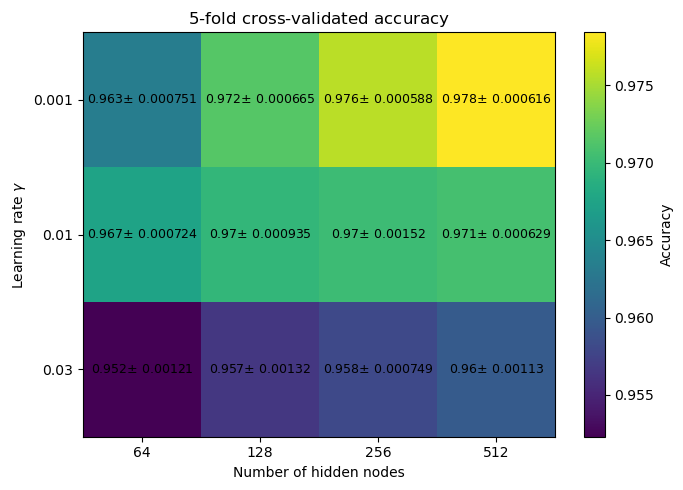

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(acc_c, cmap="viridis", aspect="auto")
ax.set_yticks(np.arange(len(gammas_c)))
ax.set_yticklabels([f"{value:g}" for value in gammas_c])
ax.set_xticks(np.arange(len(hiddens_c)))
ax.set_xticklabels([f"{value:g}" for value in hiddens_c])
ax.set_ylabel("Learning rate $\\gamma$")
ax.set_xlabel("Number of hidden nodes")
ax.set_title("$5$-fold cross-validated accuracy")


for row in range(acc_c.shape[0]):
    for col in range(acc_c.shape[1]):
        label = f"{acc_c[row, col]:.3g}$\\pm$ {se_c[row,col]:.3g}"
        ax.text(col, row, label, ha="center", va="center", fontsize = 9, color="black", linespacing = 1.1)

fig.colorbar(heatmap, ax=ax, label="Accuracy")
fig.tight_layout()
plt.show()

The $1$ standard error rule, doesn't help us choose here, as the best model lies well over one standard error over the rest. We choose $\gamma = 10^{-3}$ and a width of $512$.

We now check regularization and number of epochs.

In [16]:
epochs_c = [15, 20, 25]
lambdas_c = [1e-5, 1e-3, 1e-1]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(gamma = 1e-3, hidden = 512, batch_size = 256), {"epochs": epochs_c, "lmbda": lambdas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(x_train, y_train)

,estimator,"EstimatorClas...1, hidden=512)"
,param_grid,"{'epochs': [15, 20, ...], 'lmbda': [1e-05, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,hidden,512


In [17]:
print(f"{len(epochs_c) * len(lambdas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_
shape_c = (len(epochs_c), len(lambdas_c))                    
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)

45 training runs in 3090 s


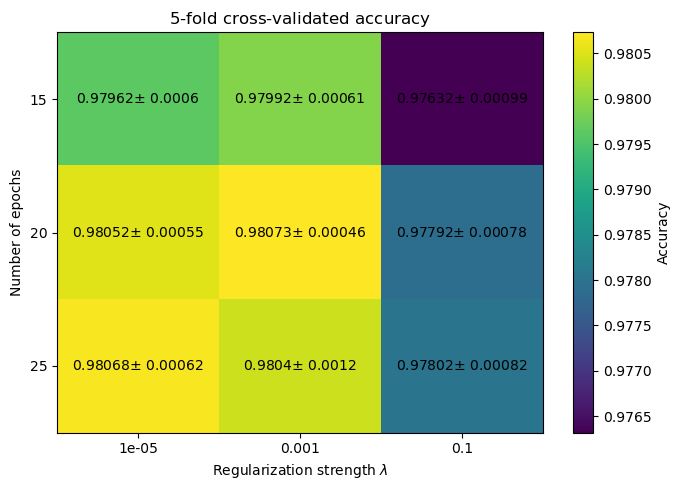

In [72]:
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(acc_c, cmap="viridis", aspect="auto")
ax.set_xticks(np.arange(len(lambdas_c)))
ax.set_xticklabels([f"{value:g}" for value in lambdas_c])
ax.set_yticks(np.arange(len(epochs_c)))
ax.set_yticklabels([f"{value:g}" for value in epochs_c])
ax.set_xlabel("Regularization strength $\\lambda$")
ax.set_ylabel("Number of epochs")
ax.set_title("$5$-fold cross-validated accuracy")


for row in range(acc_c.shape[0]):
    for col in range(acc_c.shape[1]):
        color = "black"
        ax.text(col, row, f"{acc_c[row, col]:.5g}$\\pm$ {se_c[row,col]:.2g}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Accuracy")
fig.tight_layout()
plt.show()

The best model, trained on the entire training set.

In [87]:
neural_net = EstimatorClassifier(
    gamma = 1e-3, epochs = 20, lmbda = 1e-3, hidden = 512, batch_size = 256
    )

In [88]:
neural_net.fit(x_train, y_train)

,hidden,512
,activation_funcs,"(<function ReL...001FCC4AB1F80>, ...)"
,activation_ders,"(<function ReL...001FCC4AB2020>, ...)"
,cost_fun,<function cro...001FCC4AB2340>
,cost_der,<function smc...001FCC4AB2520>
,random_seed,2026
,gamma,0.001
,epochs,20
,batch_size,256
,lmbda,0.001


In [75]:
training_accuracy = accuracy_score(y_train, neural_net.predict(x_train))
test_accuracy = accuracy_score(y_test, neural_net.predict(x_test))
se = np.sqrt(test_accuracy * (1 - test_accuracy) / len(y_test))

In [76]:
print(f"Best model training accuracy: {training_accuracy}")
print(f"Best model test accuracy: {test_accuracy} +- {se:.2g}")
print(f"95% confidence interval: {test_accuracy - (1.96 * se):.4g} - {test_accuracy + (1.96 * se):.4g}")

Best model training accuracy: 0.9989833333333333
Best model test accuracy: 0.9812 +- 0.0014
95% confidence interval: 0.9785 - 0.9839


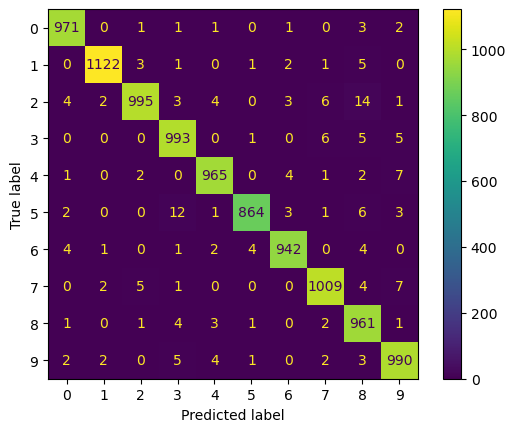

In [77]:
y_pred = neural_net.predict(x_test)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot(cmap = "viridis")

plt.show()

Guess only most frequent number baseline:

In [84]:
digits, counts = np.unique(y_train, return_counts = True)
guess = digits[np.argmax(counts)]
y_tilde_f = np.zeros_like(y_test) + guess
accuracy_f = accuracy_score(y_test, y_tilde_f)
se_f = np.sqrt(accuracy_f * (1 - accuracy_f) / len(y_test))

In [86]:
print(f"Guess only most frequent number in training set:")
print(f"Model Accuracy: {accuracy_f:.4f}+-{se_f:.4f}")
print(f"95% confidence interval: {accuracy_f - 1.96*se_f:.4f} - {accuracy_f + 1.96*se_f:.4f}")

Guess only most frequent number in training set:
Model Accuracy: 0.1135+-0.0032
95% confidence interval: 0.1073 - 0.1197


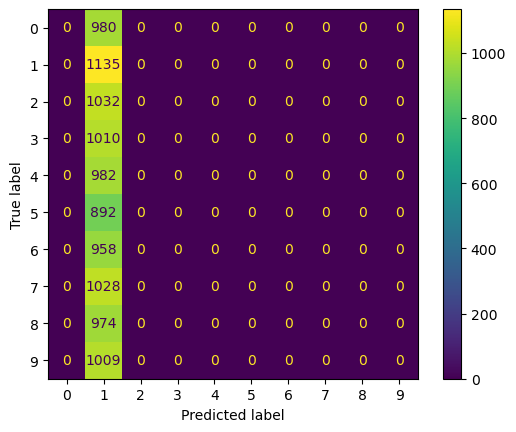

In [89]:
cm_log = confusion_matrix(y_test, y_tilde_f)

disp = ConfusionMatrixDisplay(confusion_matrix = cm_log)
disp.plot(cmap = "viridis")

plt.show()

Logistic regression baseline:

In [78]:
model = LogisticRegression(solver = "saga", max_iter = 1000, random_state = 2026)
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,2026
,solver,'saga'
,max_iter,1000
,multi_class,'deprecated'


In [79]:
y_pred_logistic = model.predict(x_test)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
se_logistic = np.sqrt(logistic_accuracy * (1 - logistic_accuracy) / len(y_test))
print(f"Logistic model:")
print(f"Model Accuracy: {logistic_accuracy:.4f}+-{se_logistic}")
print(f"95% confidence interval: {logistic_accuracy - 1.96*se_logistic:.4f} - {logistic_accuracy + 1.96*se_logistic:.4f}")

Logistic model:
Model Accuracy: 0.9257+-0.0026225847936720754
95% confidence interval: 0.9206 - 0.9308


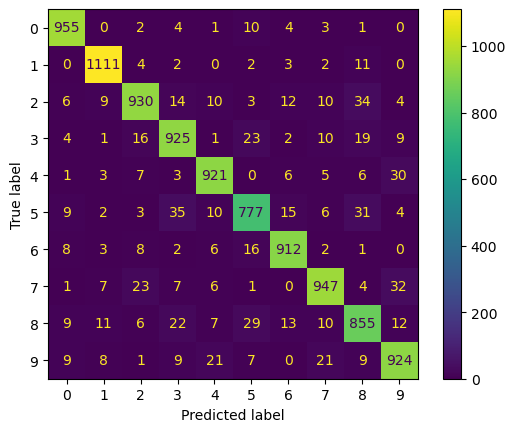

In [80]:
cm_log = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(confusion_matrix = cm_log)
disp.plot(cmap = "viridis")

plt.show()